In [0]:
 ! pip install -q kaggle

In [0]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle.json': b'{"username":"singhsandeep102","key":"e2a7905d22e1e731b4a36884faec8c6f"}'}

In [0]:
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/

mkdir: cannot create directory ‘/root/.kaggle’: File exists


In [0]:
! chmod 600 ~/.kaggle/kaggle.json

In [0]:
! kaggle datasets list

ref                                                           title                                                size  lastUpdated          downloadCount  
------------------------------------------------------------  --------------------------------------------------  -----  -------------------  -------------  
allen-institute-for-ai/CORD-19-research-challenge             COVID-19 Open Research Dataset Challenge (CORD-19)    3GB  2020-05-27 21:50:10          71785  
roche-data-science-coalition/uncover                          UNCOVER COVID-19 Challenge                          179MB  2020-05-21 18:57:53          10483  
kushshah95/the-insurance-company-tic-benchmark                The Insurance Company (TIC) Benchmark               262KB  2020-05-27 16:36:41              1  
kianwee/agricultural-raw-material-prices-19902020             Agricultural Raw Material prices (1990-2020)         23KB  2020-05-27 04:51:29              0  
jessicali9530/animal-crossing-new-horizons-nookplaza

In [0]:
!kaggle datasets download -d gpiosenka/100-bird-species

100-bird-species.zip: Skipping, found more recently modified local copy (use --force to force download)


In [0]:
!ls

 100-bird-species.zip  'kaggle (1).json'   model.png	 test	 valid
 consolidated	        kaggle.json	   sample_data	 train


In [0]:
!unzip \*.zip

Streaming output truncated to the last 5000 lines.
  inflating: train/SPANGLED COTINGA/040.jpg  
  inflating: train/SPANGLED COTINGA/041.jpg  
  inflating: train/SPANGLED COTINGA/042.jpg  
  inflating: train/SPANGLED COTINGA/043.jpg  
  inflating: train/SPANGLED COTINGA/044.jpg  
  inflating: train/SPANGLED COTINGA/045.jpg  
  inflating: train/SPANGLED COTINGA/046.jpg  
  inflating: train/SPANGLED COTINGA/047.jpg  
  inflating: train/SPANGLED COTINGA/048.jpg  
  inflating: train/SPANGLED COTINGA/049.jpg  
  inflating: train/SPANGLED COTINGA/050.jpg  
  inflating: train/SPANGLED COTINGA/051.jpg  
  inflating: train/SPANGLED COTINGA/052.jpg  
  inflating: train/SPANGLED COTINGA/053.jpg  
  inflating: train/SPANGLED COTINGA/054.jpg  
  inflating: train/SPANGLED COTINGA/055.jpg  
  inflating: train/SPANGLED COTINGA/056.jpg  
  inflating: train/SPANGLED COTINGA/057.jpg  
  inflating: train/SPANGLED COTINGA/058.jpg  
  inflating: train/SPANGLED COTINGA/059.jpg  
  inflating: train/SPANGLED C

In [0]:
import matplotlib.pyplot as plt
import numpy as np
from random import shuffle
import cv2
from random import shuffle
from tqdm import tqdm
import tensorflow
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import TensorBoard
import os
import os
import zipfile
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [0]:
data_dir = ''

In [0]:
train_dir = os.path.join(data_dir, 'train')
validation_dir = os.path.join(data_dir, 'valid')
test_dir = os.path.join(data_dir, 'test')
train_dir

'train'

In [0]:
classes=os.listdir(train_dir)
label_code = {}
code_label = {}
a = 0
for i in classes:
    label_code.update({i:a})
    code_label.update({a:i})
    a+=1

In [0]:
code_label

{0: 'YELLOW HEADED BLACKBIRD',
 1: 'PAINTED BUNTIG',
 2: 'GLOSSY IBIS',
 3: 'COMMON HOUSE MARTIN',
 4: 'CINNAMON TEAL',
 5: 'MANDRIN DUCK',
 6: 'TOWNSENDS WARBLER',
 7: 'FLAME TANAGER',
 8: 'BLACK THROATED WARBLER',
 9: 'TREE SWALLOW',
 10: 'CROW',
 11: 'MASKED BOOBY',
 12: 'BLACK VULTURE',
 13: 'PUFFIN',
 14: 'HOODED MERGANSER',
 15: 'RUBY THROATED HUMMINGBIRD',
 16: 'COCK OF THE  ROCK',
 17: 'WILD TURKEY',
 18: 'STORK BILLED KINGFISHER',
 19: 'WILSONS BIRD OF PARADISE',
 20: 'FLAMINGO',
 21: 'GILDED FLICKER',
 22: 'BAY-BREASTED WARBLER',
 23: 'BALD EAGLE',
 24: 'RED HEADED WOODPECKER',
 25: 'WATTLED CURASSOW',
 26: 'BLACKBURNIAM WARBLER',
 27: 'PINK ROBIN',
 28: 'CHARA DE COLLAR',
 29: 'MALEO',
 30: 'CHIPPING SPARROW',
 31: 'ROSY FACED LOVEBIRD',
 32: 'RED FACED WARBLER',
 33: 'SHOEBILL',
 34: 'ANTBIRD',
 35: 'NORTHERN PARULA',
 36: 'NORTHERN CARDINAL',
 37: 'SPLENDID WREN',
 38: 'HOUSE FINCH',
 39: 'CALIFORNIA CONDOR',
 40: 'TEAL DUCK',
 41: 'DOWNY WOODPECKER',
 42: 'TURQUOISE MOTMO

In [0]:
train_datagen = ImageDataGenerator(rescale=1./255,samplewise_center=True,samplewise_std_normalization=True,fill_mode='nearest')
test_datagen = ImageDataGenerator(rescale=1./255,samplewise_center=True,samplewise_std_normalization=True,fill_mode='nearest')
validation_datagen = ImageDataGenerator(rescale=1./255,samplewise_center=True,samplewise_std_normalization=True,fill_mode='nearest')

In [0]:
train_generator = train_datagen.flow_from_directory(train_dir,target_size=(224, 224), batch_size=128,shuffle=True,class_mode='categorical')
validation_generator = validation_datagen.flow_from_directory(validation_dir,target_size=(224, 224), batch_size=64,shuffle=True,class_mode='categorical')
test_generator = test_datagen.flow_from_directory(test_dir,target_size=(224, 224), batch_size=64,shuffle=False,class_mode='categorical')

Found 27503 images belonging to 200 classes.
Found 1000 images belonging to 200 classes.
Found 1000 images belonging to 200 classes.


In [0]:
from tensorflow.keras import regularizers

**VGG16 Transfer learning**

In [0]:
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input
import numpy as np

model = VGG16(weights='imagenet', include_top=False)

In [0]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.summary()

Model: "vgg16"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
block1_conv1 (Conv2D)        (None, 224, 224, 64)      1792      
_________________________________________________________________
block1_conv2 (Conv2D)        (None, 224, 224, 64)      36928     
_________________________________________________________________
block1_pool (MaxPooling2D)   (None, 112, 112, 64)      0         
_________________________________________________________________
block2_conv1 (Conv2D)        (None, 112, 112, 128)     73856     
_________________________________________________________________
block2_conv2 (Conv2D)        (None, 112, 112, 128)     147584    
_________________________________________________________________
block2_pool (MaxPooling2D)   (None, 56, 56, 128)       0     

In [0]:
from tensorflow.keras.layers import Dropout, Flatten, Dense
from tensorflow.keras.optimizers import Adam
for layer in base_model.layers: 
  layer.trainable = False
  print('Layer ' + layer.name + ' frozen.')

# We take the last layer of our the model and add it to our classifier
last = base_model.layers[-1].output
x = Flatten()(last)
x = Dense(10000)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)                          
x = layers.Dropout(rate=.5)(x)
#x = Dense(8000, activation='relu')(x)
x = Dense(10000)(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)                          
x = layers.Dropout(rate=.4)(x)
#x = Dropout(0.4)(x)
x = Dense(4000, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(700, activation='relu')(x)
x = Dense(200, activation='softmax')(x)
modelVGG = Model(base_model.input, x)
modelVGG.compile(optimizer=SGD(lr=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

modelVGG.summary()

Layer input_2 frozen.
Layer block1_conv1 frozen.
Layer block1_conv2 frozen.
Layer block1_pool frozen.
Layer block2_conv1 frozen.
Layer block2_conv2 frozen.
Layer block2_pool frozen.
Layer block3_conv1 frozen.
Layer block3_conv2 frozen.
Layer block3_conv3 frozen.
Layer block3_pool frozen.
Layer block4_conv1 frozen.
Layer block4_conv2 frozen.
Layer block4_conv3 frozen.
Layer block4_pool frozen.
Layer block5_conv1 frozen.
Layer block5_conv2 frozen.
Layer block5_conv3 frozen.
Layer block5_pool frozen.
Model: "model_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
block1_conv1 (Conv2D)        (None, 224, 224, 64)      1792      
_________________________________________________________________
block1_conv2 (Conv2D)        (None, 224, 224, 64)      36928     
__________________

In [0]:
Evaluation2 = modelVGG.fit_generator(train_generator,steps_per_epoch=202,epochs=40,verbose=1,validation_data= validation_generator)

Instructions for updating:
Please use Model.fit, which supports generators.
Epoch 1/40
202/202 [==============================] - 82s 404ms/step - loss: 5.1289 - accuracy: 0.0346 - val_loss: 4.3693 - val_accuracy: 0.2100
Epoch 2/40
202/202 [==============================] - 79s 393ms/step - loss: 3.8555 - accuracy: 0.1968 - val_loss: 2.4895 - val_accuracy: 0.4800
Epoch 3/40
202/202 [==============================] - 82s 405ms/step - loss: 2.5076 - accuracy: 0.4190 - val_loss: 1.4875 - val_accuracy: 0.6540
Epoch 4/40
202/202 [==============================] - 80s 396ms/step - loss: 1.7139 - accuracy: 0.5749 - val_loss: 0.9830 - val_accuracy: 0.7690
Epoch 5/40
202/202 [==============================] - 79s 393ms/step - loss: 1.2591 - accuracy: 0.6721 - val_loss: 0.7267 - val_accuracy: 0.8170
Epoch 6/40
202/202 [==============================] - 79s 391ms/step - loss: 0.9648 - accuracy: 0.7431 - val_loss: 0.5938 - val_accuracy: 0.8470
Epoch 7/40
202/202 [==============================] - 

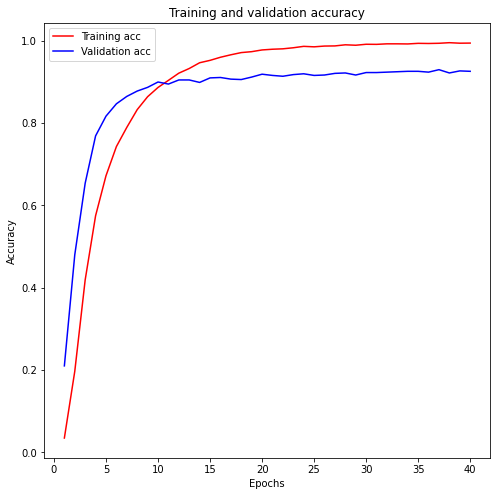

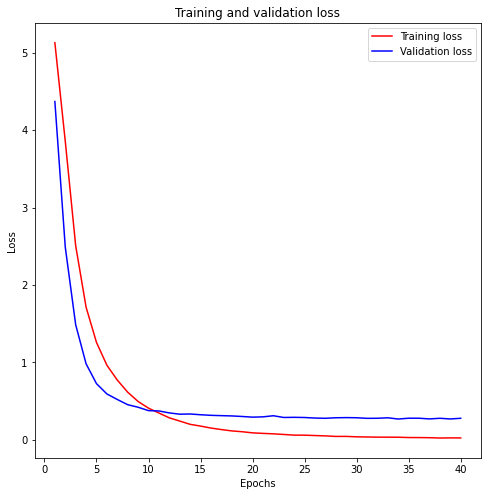

In [0]:
acc = Evaluation2.history['accuracy']
val_acc = Evaluation2.history['val_accuracy']
loss = Evaluation2.history['loss']
val_loss = Evaluation2.history['val_loss']
epochs = range(1, len(acc) + 1)

#Plotting Training and Validation accuracy

#plt.style.use("ggplot")
plt.figure(figsize=(8,8))
plt.title('Training and validation accuracy')
plt.plot(epochs, acc, 'red', label='Training acc')
plt.plot(epochs, val_acc, 'blue', label='Validation acc')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
#Plotting Training and Validation loss
plt.figure(figsize=(8,8))
plt.title('Training and validation loss')
plt.plot(epochs, loss, 'red', label='Training loss')
plt.plot(epochs, val_loss, 'blue', label='Validation loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [0]:
modelVGG.evaluate_generator(test_generator)

Instructions for updating:
Please use Model.evaluate, which supports generators.


[0.19078639149665833, 0.9459999799728394]

In [0]:
Y_pred = modelVGG.predict_generator(test_generator,verbose=1)

Instructions for updating:
Please use Model.predict, which supports generators.
16/16 [==============================] - 3s 164ms/step


**Confusion Matrix**

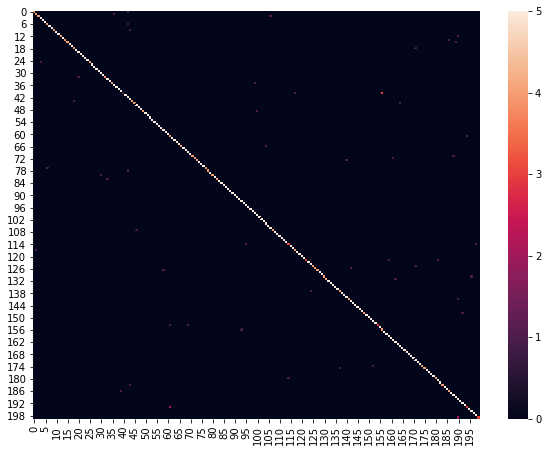

In [0]:
labels = (test_generator.class_indices)
labels = dict((v,k) for k,v in labels.items())
predicted_class_indices=np.argmax(Y_pred,axis=1)
predictions = [labels[k] for k in predicted_class_indices]
test_labels=[labels[k] for k in test_generator.classes]

plt.subplots(figsize=(10,7.5))
sns.heatmap(confusion_matrix(test_labels, predictions))

**F1 Score**

In [0]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

predictions = modelVGG.predict_generator(test_generator)
#test_steps_per_epoch = numpy.math.ceil(validation_generator.samples / validation_generator.batch_size)
predicted_classes = np.argmax(predictions, axis=-1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())
report = classification_report(true_classes, predicted_classes, target_names=class_labels)
print(report)   


                           precision    recall  f1-score   support

        AFRICAN FIREFINCH       1.00      0.80      0.89         5
                ALBATROSS       0.80      0.80      0.80         5
     ALEXANDRINE PARAKEET       1.00      0.80      0.89         5
          AMERICAN AVOCET       0.83      1.00      0.91         5
         AMERICAN BITTERN       1.00      1.00      1.00         5
            AMERICAN COOT       1.00      1.00      1.00         5
       AMERICAN GOLDFINCH       0.80      0.80      0.80         5
         AMERICAN KESTREL       1.00      1.00      1.00         5
           AMERICAN PIPIT       1.00      1.00      1.00         5
        AMERICAN REDSTART       1.00      0.80      0.89         5
                  ANHINGA       1.00      1.00      1.00         5
        ANNAS HUMMINGBIRD       1.00      1.00      1.00         5
                  ANTBIRD       1.00      0.80      0.89         5
          ARARIPE MANAKIN       1.00      1.00      1.00     